In [1]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import skimage.feature as feature

import warnings
import mahotas
warnings.filterwarnings("ignore")

In [2]:
GROUP = "C8"
DTYPE="RGB"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C8_10,30,"[DATA/TRAINING/C8/C8_10/IMG_8678.HEIC, DATA/TR..."
1,C8_11,25,"[DATA/TRAINING/C8/C8_11/IMG_8730.HEIC, DATA/TR..."
2,C8_12,25,"[DATA/TRAINING/C8/C8_12/IMG_8761.HEIC, DATA/TR..."
3,C8_13,25,"[DATA/TRAINING/C8/C8_13/IMG_8793.HEIC, DATA/TR..."
4,C8_14,25,"[DATA/TRAINING/C8/C8_14/IMG_8823.HEIC, DATA/TR..."
5,C8_15,26,"[DATA/TRAINING/C8/C8_15/IMG_8855.HEIC, DATA/TR..."
6,C8_16,25,"[DATA/TRAINING/C8/C8_16/IMG_8886.HEIC, DATA/TR..."


In [3]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [4]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [5]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

In [6]:
def read_image(pic_path):
    ext = pic_path.split(".")[1]
    if ext=="HEIC":
        return read_imgHEIC(pic_path)
    else:
        img=cv2.imread(pic_path)
        return img

In [7]:
def bgr_histogram(image, bins):
    #print(mask)
    #image = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    #The 3D color histogram is extracted from the mask area of the image using the bin number of each channel provided
    hist = cv2.calcHist([image], [0, 1, 2], None, [bins, bins, bins], [0, 256, 0, 256, 0, 256])
    hist = cv2.normalize(hist, hist).flatten()
    #Return histogram
    return hist

Text(0.5, 1.0, '16% IMG_8906.HEIC')

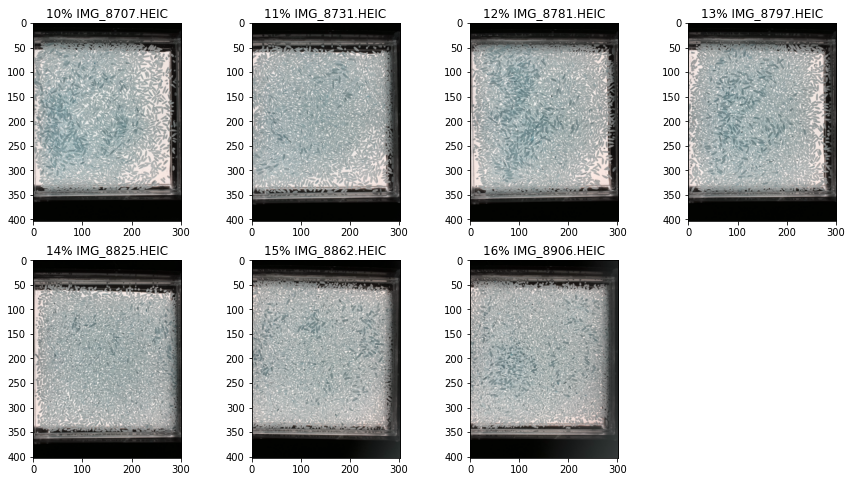

In [8]:
fig=plt.figure(figsize=(15, 8)) 
ax1 = fig.add_subplot(2,4,1); path_image= random.randint(0, 25)
image = read_image(data_path[0][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10% " + data_path[0][path_image].split("/")[4])
ax2 = fig.add_subplot(2,4,2); path_image= random.randint(0, 25)
image = read_image(data_path[1][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11% "+ data_path[1][path_image].split("/")[4])
ax3 = fig.add_subplot(2,4,3); path_image= random.randint(0, 25)
image = read_image(data_path[2][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12% "+ data_path[2][path_image].split("/")[4])
ax4 = fig.add_subplot(2,4,4); path_image= random.randint(0, 25)
image = read_image(data_path[3][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13% "+ data_path[3][path_image].split("/")[4])
ax5 = fig.add_subplot(2,4,5); path_image= random.randint(0, 25)
image = read_image(data_path[4][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14% "+ data_path[4][path_image].split("/")[4])
ax6 = fig.add_subplot(2,4,6); path_image= random.randint(0, 25)
image = read_image(data_path[5][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15% "+ data_path[5][path_image].split("/")[4])
ax7 = fig.add_subplot(2,4,7); path_image= random.randint(0, 25)
image = read_image(data_path[6][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16% "+ data_path[6][path_image].split("/")[4])

In [159]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
scale=3
bins=16
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        
        arr_img_hist.append(bgr_histogram(image, bins))
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["bins"] = bins
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [160]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,4093,4094,4095,scale,bins,height,width,channels,IMAGENAME,HUMIDITY
0,0.615476,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,3,16,120,90,3,IMG_8678.HEIC,10
1,0.570490,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000709,0.0,3,16,120,90,3,IMG_8679.HEIC,10
2,0.591419,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,3,16,120,90,3,IMG_8680.HEIC,10
3,0.607039,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,3,16,120,90,3,IMG_8682.HEIC,10
4,0.548913,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,3,16,120,90,3,IMG_8686.HEIC,10
5,0.534889,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000332,0.0,3,16,120,90,3,IMG_8693.HEIC,10
6,0.570137,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,3,16,120,90,3,IMG_8701.HEIC,10
7,0.574032,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,3,16,120,90,3,IMG_8702.HEIC,10
8,0.585100,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000367,0.0,3,16,120,90,3,IMG_8703.HEIC,10
9,0.558978,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,3,16,120,90,3,IMG_8704.HEIC,10


# Classification

In [161]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-7]
#X

In [162]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [163]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [164]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [165]:
TYPE="CV"

In [166]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [167]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["bins"]=bins; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,bins,height,width,channels
0,1,0.684211,0.759524,0.714286,0.736210,RGB,C8,RF_C,3,16,120,90,3
1,2,0.833333,0.845238,0.833333,0.839243,RGB,C8,RF_C,3,16,120,90,3
2,3,0.666667,0.795238,0.666667,0.725299,RGB,C8,RF_C,3,16,120,90,3
3,4,0.500000,0.571429,0.476190,0.519481,RGB,C8,RF_C,3,16,120,90,3
4,5,0.833333,0.871429,0.809524,0.839336,RGB,C8,RF_C,3,16,120,90,3
5,6,0.722222,0.788095,0.738095,0.762276,RGB,C8,RF_C,3,16,120,90,3
6,7,0.500000,0.509524,0.523810,0.516568,RGB,C8,RF_C,3,16,120,90,3
7,8,0.444444,0.511905,0.452381,0.480306,RGB,C8,RF_C,3,16,120,90,3
8,9,0.666667,0.752381,0.690476,0.720101,RGB,C8,RF_C,3,16,120,90,3
9,10,0.611111,0.707483,0.619048,0.660317,RGB,C8,RF_C,3,16,120,90,3


In [168]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,RGB,C8,RF_C,0.646199,0.652381,0.679914,0.711224


### MLP Classifier

In [169]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [170]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [171]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["bins"]=bins; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,bins,height,width,channels
0,1,0.789474,0.833333,0.809524,0.821256,RGB,C8,MLP_C,3,16,120,90,3
1,2,0.888889,0.904762,0.880952,0.892698,RGB,C8,MLP_C,3,16,120,90,3
2,3,0.666667,0.726190,0.666667,0.695157,RGB,C8,MLP_C,3,16,120,90,3
3,4,0.722222,0.785714,0.738095,0.761161,RGB,C8,MLP_C,3,16,120,90,3
4,5,0.777778,0.845238,0.761905,0.801411,RGB,C8,MLP_C,3,16,120,90,3
5,6,0.666667,0.773810,0.690476,0.729772,RGB,C8,MLP_C,3,16,120,90,3
6,7,0.777778,0.821429,0.809524,0.815433,RGB,C8,MLP_C,3,16,120,90,3
7,8,0.722222,0.761905,0.738095,0.749811,RGB,C8,MLP_C,3,16,120,90,3
8,9,0.888889,0.928571,0.880952,0.904135,RGB,C8,MLP_C,3,16,120,90,3
9,10,0.722222,0.800000,0.714286,0.754717,RGB,C8,MLP_C,3,16,120,90,3


In [172]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,RGB,C8,MLP_C,0.762281,0.769048,0.792555,0.818095


### XGBoost Classifier

In [173]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [174]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["bins"]=bins; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,bins,height,width,channels
0,1,0.526316,0.652381,0.523810,0.581068,RGB,C8,XGB_C,3,16,120,90,3
1,2,0.722222,0.785714,0.738095,0.761161,RGB,C8,XGB_C,3,16,120,90,3
2,3,0.777778,0.797619,0.761905,0.779353,RGB,C8,XGB_C,3,16,120,90,3
3,4,0.555556,0.630952,0.571429,0.599717,RGB,C8,XGB_C,3,16,120,90,3
4,5,0.722222,0.821429,0.738095,0.777535,RGB,C8,XGB_C,3,16,120,90,3
5,6,0.611111,0.619048,0.595238,0.606909,RGB,C8,XGB_C,3,16,120,90,3
6,7,0.777778,0.845238,0.761905,0.801411,RGB,C8,XGB_C,3,16,120,90,3
7,8,0.833333,0.895238,0.857143,0.875776,RGB,C8,XGB_C,3,16,120,90,3
8,9,0.777778,0.833333,0.785714,0.808824,RGB,C8,XGB_C,3,16,120,90,3
9,10,0.611111,0.714286,0.642857,0.676692,RGB,C8,XGB_C,3,16,120,90,3


In [175]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,RGB,C8,XGB_C,0.69152,0.697619,0.726845,0.759524


# External validation

In [176]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C8_10,5,"[DATA/TEST/C8/C8_10/IMG_8685.HEIC, DATA/TEST/C..."
1,C8_11,5,"[DATA/TEST/C8/C8_11/IMG_8732.HEIC, DATA/TEST/C..."
2,C8_12,5,"[DATA/TEST/C8/C8_12/IMG_8762.HEIC, DATA/TEST/C..."
3,C8_13,5,"[DATA/TEST/C8/C8_13/IMG_8792.HEIC, DATA/TEST/C..."
4,C8_14,5,"[DATA/TEST/C8/C8_14/IMG_8827.HEIC, DATA/TEST/C..."
5,C8_15,5,"[DATA/TEST/C8/C8_15/IMG_8854.HEIC, DATA/TEST/C..."
6,C8_16,5,"[DATA/TEST/C8/C8_16/IMG_8901.HEIC, DATA/TEST/C..."


In [177]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [178]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        arr_img_hist.append(bgr_histogram(image, bins))
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["bins"] = bins
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [179]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,4093,4094,4095,scale,bins,height,width,channels,IMAGENAME,HUMIDITY
0,0.615504,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000389,0.0,3,16,120,90,3,IMG_8685.HEIC,10
1,0.534593,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,3,16,120,90,3,IMG_8687.HEIC,10
2,0.530321,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,3,16,120,90,3,IMG_8688.HEIC,10
3,0.597945,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000374,0.0,3,16,120,90,3,IMG_8696.HEIC,10
4,0.523544,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,3,16,120,90,3,IMG_8699.HEIC,10
0,0.582675,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,3,16,120,90,3,IMG_8732.HEIC,11
1,0.617300,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,3,16,120,90,3,IMG_8735.HEIC,11
2,0.609279,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,3,16,120,90,3,IMG_8737.HEIC,11
3,0.552450,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,3,16,120,90,3,IMG_8739.HEIC,11
4,0.559385,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,3,16,120,90,3,IMG_8740.HEIC,11


In [180]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [181]:
X_test = dtFeaturesTest.values[:, :-7]
#X_test

In [182]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [183]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [184]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.43      0.60      0.50         5
     Class 1       0.83      1.00      0.91         5
     Class 2       1.00      0.60      0.75         5
     Class 3       0.50      0.20      0.29         5
     Class 4       0.57      0.80      0.67         5
     Class 5       0.80      0.80      0.80         5
     Class 6       0.80      0.80      0.80         5

    accuracy                           0.69        35
   macro avg       0.70      0.69      0.67        35
weighted avg       0.70      0.69      0.67        35



## MLP

In [185]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [186]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.83      1.00      0.91         5
     Class 1       0.80      0.80      0.80         5
     Class 2       1.00      0.60      0.75         5
     Class 3       0.40      0.40      0.40         5
     Class 4       0.50      0.80      0.62         5
     Class 5       1.00      0.80      0.89         5
     Class 6       1.00      0.80      0.89         5

    accuracy                           0.74        35
   macro avg       0.79      0.74      0.75        35
weighted avg       0.79      0.74      0.75        35



## XGBC

In [187]:
y_pred = modelXGBC.predict(X_test_scale) 

In [188]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.67      0.80      0.73         5
     Class 1       1.00      1.00      1.00         5
     Class 2       0.60      0.60      0.60         5
     Class 3       0.50      0.60      0.55         5
     Class 4       0.60      0.60      0.60         5
     Class 5       1.00      0.80      0.89         5
     Class 6       1.00      0.80      0.89         5

    accuracy                           0.74        35
   macro avg       0.77      0.74      0.75        35
weighted avg       0.77      0.74      0.75        35

